# AR Detection Skill — WNet vs MARS (modified tARget-v3)

**Goal.** Evaluate the WNet `AR_detection` masks against an independent atmospheric-river
reference, the **`MARS`** variable (*"Atmospheric river shapes detected by the modified
tARget-v3 algorithm"*) carried in the monthly ERA5 data files. Pixel-level skill is
reported for two periods, matching the hurricane evaluation:

* **primary** 2006–2024 (in-period generalization)
* **oop** 1980–2005 (out-of-period; pre-modern ERA5 obs era)

**Caveats.**
* These predictions come from the **prior-vintage checkpoint**
  (`MCS_enhanced_trial61/ETCs_enchanced_test_etc_21`), *not* Trail11/epoch54.
* The in-loop Trail11 validation IoU for AR was **0.881 vs the model's training heuristic**
  (an IVT-percentile mask). `MARS` is an *algorithmically different* AR definition
  (tARget-v3), so this offline IoU is a genuinely **independent** check and is expected
  to sit below 0.881. As a reference-reliability control we also note the agreement
  between the two independent heuristics `MARS` and `ARS` (unmodified tARget-v3).
* AR has no track concept, so skill is pixel-level only (IoU / Dice / POD / FAR / BIAS).

Grids match exactly (721×1440, 6-hourly, lat 90→−90); the only adjustment is the
prediction's longitude convention (−180–180 → 0–360).

In [1]:
import os, sys, glob
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import cartopy.crs as ccrs
import cartopy.feature as cfeature

DATA_DIR = "/lustre/orion/cli138/proj-shared/z7a/Storms_data/data"
PRED_DIR = ("/lustre/orion/proj-shared/cli138/z7a/Storms_data/Storms_precipitation_notebooks/"
            "Percentile_ARs_detection/ARs_Hurricanes_ETCs_MCS/MCS_enhanced_trial61/"
            "ETCs_enchanced_test_etc_21")
TARGET_VAR = "MARS"        # benchmark = modified tARget-v3 AR shapes
PRED_VAR   = "AR_detection"
PERIODS    = {"oop": (1980, 2005), "primary": (2006, 2024)}
OUT_DIR    = "evaluations/ar_mars_eval"   # relative to WNet_parallel_global_code/
CACHE_NPZ  = os.path.join(OUT_DIR, "ar_eval_cache.npz")
MONTHLY_CSV = os.path.join(OUT_DIR, "ar_monthly.csv")
MONTH_STRIDE = 1            # >1 = fast smoke-test subset
EPS = 1e-12
os.makedirs(OUT_DIR, exist_ok=True)
print("cache present:", os.path.exists(CACHE_NPZ))

cache present: True


## Helpers + streaming pass

The heavy pass (540 monthly file-pairs, ~1 GB transient each, I/O-bound ~tens of
minutes) is cached to `ar_eval_cache.npz` + `ar_monthly.csv` by
`evaluations/ar_mars_eval/build_ar_cache.py`. If the cache exists we load it;
otherwise the same logic runs inline.

In [2]:
def period_of(year):
    for name, (y0, y1) in PERIODS.items():
        if y0 <= year <= y1:
            return name
    return None

def load_target(year, month):
    f = os.path.join(DATA_DIR, f"era5dara_{year:04d}{month:02d}.nc")
    if not os.path.exists(f):
        return None, None
    ds = xr.open_dataset(f)
    if TARGET_VAR not in ds.data_vars:
        ds.close(); return None, None
    arr = (ds[TARGET_VAR].values > 0)
    coords = (ds.latitude.values, ds.longitude.values)
    ds.close()
    return arr, coords

def load_pred(year, month):
    f = os.path.join(PRED_DIR, f"era5dara_{year:04d}{month:02d}_{PRED_VAR}.nc")
    if not os.path.exists(f):
        return None
    ds = xr.open_dataset(f)
    da = ds[PRED_VAR].assign_coords(longitude=(ds[PRED_VAR].longitude % 360)).sortby("longitude")
    arr = (da.values > 0.5)
    ds.close()
    return arr

def metrics_from_counts(tp, fp, fn, tn=None):
    out = dict(
        IoU=tp/(tp+fp+fn+EPS), Dice=2*tp/(2*tp+fp+fn+EPS),
        Precision=tp/(tp+fp+EPS), POD=tp/(tp+fn+EPS),
        FAR=fp/(tp+fp+EPS), BIAS=(tp+fp)/(tp+fn+EPS))
    out["F1"] = out["Dice"]
    if tn is not None:
        num = 2*(tp*tn - fp*fn)
        den = (tp+fn)*(fn+tn) + (tp+fp)*(fp+tn) + EPS
        out["HSS"] = num/den
    return out

In [3]:
def run_streaming_pass(stride=1):
    H = W = None; lat = lon = None
    acc = {p: dict(tp=0, fp=0, fn=0, tn=0, n_t=0) for p in PERIODS}
    pix = {}; monthly = []
    months = [(y, m) for y in range(1980, 2025) for m in range(1, 13)][::stride]
    for i, (y, m) in enumerate(months):
        p = period_of(y)
        if p is None: continue
        tgt, coords = load_target(y, m); prd = load_pred(y, m)
        if tgt is None or prd is None or tgt.shape != prd.shape: continue
        if H is None:
            lat, lon = coords; H, W = tgt.shape[1], tgt.shape[2]
            for pp in PERIODS:
                pix[pp] = {k: np.zeros((H, W), np.int64) for k in ("tp", "fp", "fn")}
        tp_pix = np.logical_and(prd, tgt).sum(0)
        fp_pix = np.logical_and(prd, ~tgt).sum(0)
        fn_pix = np.logical_and(~prd, tgt).sum(0)
        nt = tgt.shape[0]
        tp, fp, fn = int(tp_pix.sum()), int(fp_pix.sum()), int(fn_pix.sum())
        tn = nt*H*W - tp - fp - fn
        for k, v in (("tp", tp), ("fp", fp), ("fn", fn), ("tn", tn), ("n_t", nt)):
            acc[p][k] += v
        pix[p]["tp"] += tp_pix; pix[p]["fp"] += fp_pix; pix[p]["fn"] += fn_pix
        monthly.append(dict(year=y, month=m, period=p, n_t=nt, tp=tp, fp=fp, fn=fn,
                            **metrics_from_counts(tp, fp, fn)))
    return acc, pix, lat, lon, pd.DataFrame(monthly)

if os.path.exists(CACHE_NPZ):
    z = np.load(CACHE_NPZ, allow_pickle=True)
    lat, lon = z["lat"], z["lon"]
    acc, pix = {}, {}
    for p in PERIODS:
        tp, fp, fn, tn, nt = z[f"{p}_scalar"]
        acc[p] = dict(tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn), n_t=int(nt))
        pix[p] = {k: z[f"{p}_pix_{k}"] for k in ("tp", "fp", "fn")}
    monthly = pd.read_csv(MONTHLY_CSV)
    print("loaded cache | stride =", int(z["stride"]))
else:
    print("no cache; running inline streaming pass (slow)...")
    acc, pix, lat, lon, monthly = run_streaming_pass(MONTH_STRIDE)
print({p: acc[p]["n_t"] for p in PERIODS})

loaded cache | stride = 1
{'oop': 37988, 'primary': 27760}


## 1 — Headline metrics (primary vs OOP)

Pixel contingency collapsed over each whole period. `FAR = FP/(TP+FP)` matches the
hurricane-eval convention (= 1 − Precision). Area-weighted rows use cos(latitude).

In [4]:
rows = []
wlat = np.cos(np.deg2rad(lat))[:, None]
for p in PERIODS:
    a = acc[p]
    mm = metrics_from_counts(a["tp"], a["fp"], a["fn"], a["tn"])
    rows.append(dict(period=p, weighting="unweighted",
                     **{k: round(mm[k], 4) for k in ("IoU","F1","Precision","POD","FAR","BIAS","HSS")},
                     hits=a["tp"], false_alarms=a["fp"], misses=a["fn"], n_timesteps=a["n_t"]))
    tpw = float((pix[p]["tp"]*wlat).sum()); fpw = float((pix[p]["fp"]*wlat).sum()); fnw = float((pix[p]["fn"]*wlat).sum())
    mw = metrics_from_counts(tpw, fpw, fnw)
    rows.append(dict(period=p, weighting="area-weighted",
                     **{k: round(mw[k], 4) for k in ("IoU","F1","Precision","POD","FAR","BIAS")},
                     HSS=np.nan, hits=np.nan, false_alarms=np.nan, misses=np.nan, n_timesteps=a["n_t"]))
head = pd.DataFrame(rows)
head.to_csv(os.path.join(OUT_DIR, "summary_ar_primary_oop.csv"), index=False)

# evaluate.py-style .txt
with open(os.path.join(OUT_DIR, "summary_ar_primary_oop.txt"), "w") as fh:
    fh.write("="*70 + "\nWNet AR Detection vs MARS (modified tARget-v3) — pixel skill\n" + "="*70 + "\n")
    fh.write(f"Predictions : {PRED_DIR}\nTarget var  : {TARGET_VAR}\n\n")
    for p in PERIODS:
        a = acc[p]; mm = metrics_from_counts(a["tp"], a["fp"], a["fn"], a["tn"])
        fh.write(f"ar_pixel_{p}:\n")
        for k in ("IoU","Dice","F1","Precision","POD","FAR","BIAS","HSS"):
            fh.write(f"  {k:<12} = {mm[k]:.6f}\n")
        for k in ("tp","fp","fn","n_t"):
            fh.write(f"  {k:<12} = {a[k]}\n")
        fh.write("\n")
print("wrote summary_ar_primary_oop.{csv,txt}")
head

wrote summary_ar_primary_oop.{csv,txt}


,period,weighting,IoU,F1,Precision,POD,FAR,BIAS,HSS,hits,false_alarms,misses,n_timesteps
0,oop,unweighted,0.3019,0.4638,0.5976,0.3789,0.4024,0.6339,0.4358,953722126.0,642077474.0,1.563529e+09,37988
1,oop,area-weighted,0.3201,0.4849,0.5512,0.4329,0.4488,0.7853,NaN,NaN,NaN,NaN,37988
2,primary,unweighted,0.2998,0.4614,0.5891,0.3791,0.4109,0.6435,0.4308,749562033.0,522717649.0,1.227522e+09,27760
3,primary,area-weighted,0.3172,0.4816,0.5389,0.4353,0.4611,0.8077,NaN,NaN,NaN,NaN,27760


## 2 — Monthly skill time series (1980–2024)

Per-month IoU / F1 / POD / FAR across the whole record; the dashed line at 2006-01
divides OOP (left) from primary (right). Flatness across the line = stable
generalization across the ERA5 observation era.

wrote ar_monthly_timeseries.png


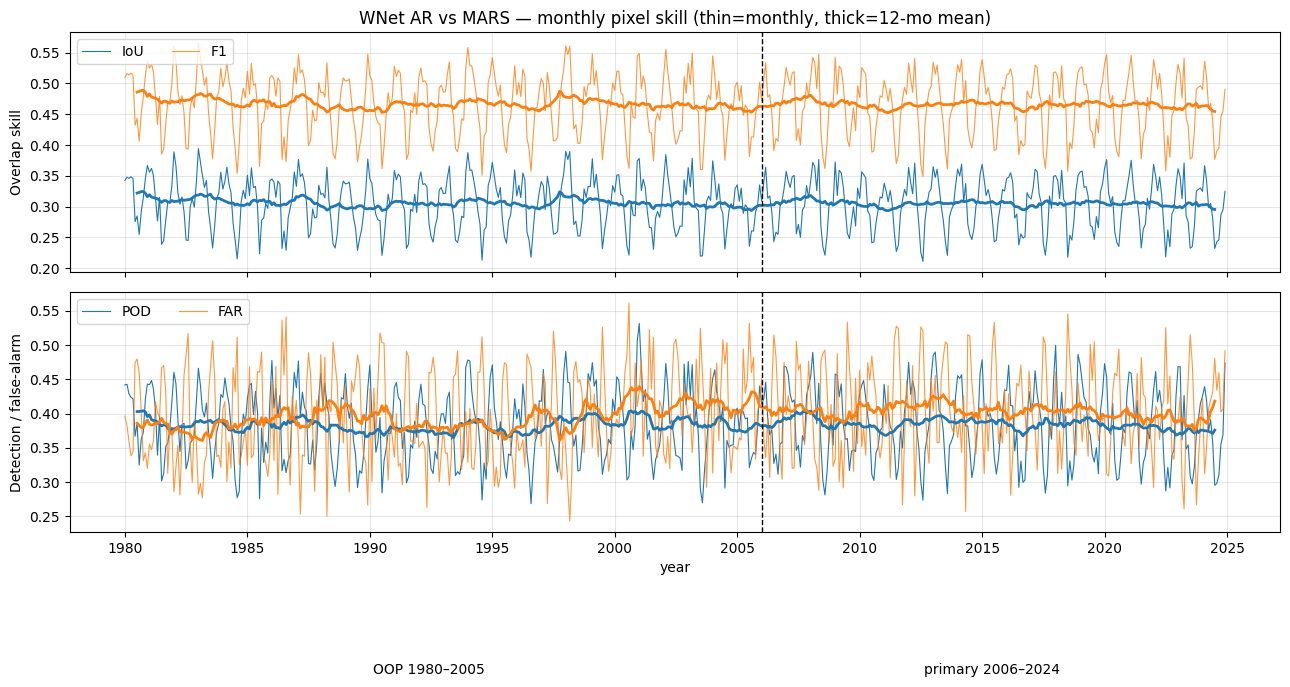

In [5]:
mdf = monthly.sort_values(["year", "month"]).copy()
mdf["date"] = pd.to_datetime(dict(year=mdf.year, month=mdf.month, day=1))
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, (a_metric, b_metric, title) in zip(
        axes, [("IoU", "F1", "Overlap skill"), ("POD", "FAR", "Detection / false-alarm")]):
    ax.plot(mdf.date, mdf[a_metric], lw=0.8, label=a_metric)
    ax.plot(mdf.date, mdf[b_metric], lw=0.8, alpha=0.8, label=b_metric)
    # 12-month rolling means for readability
    ax.plot(mdf.date, mdf[a_metric].rolling(12, center=True).mean(), lw=2, color="C0")
    ax.plot(mdf.date, mdf[b_metric].rolling(12, center=True).mean(), lw=2, color="C1")
    ax.axvline(pd.Timestamp("2006-01-01"), ls="--", color="k", lw=1)
    ax.set_ylabel(title); ax.legend(loc="upper left", ncol=2); ax.grid(alpha=0.3)
axes[0].set_title("WNet AR vs MARS — monthly pixel skill (thin=monthly, thick=12-mo mean)")
axes[1].text(pd.Timestamp("1992-06-01"), 0.02, "OOP 1980–2005", ha="center")
axes[1].text(pd.Timestamp("2015-06-01"), 0.02, "primary 2006–2024", ha="center")
axes[-1].set_xlabel("year")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "ar_monthly_timeseries.png"), dpi=130)
print("wrote ar_monthly_timeseries.png"); plt.show()

## 3 — Global spatial maps (per period)

For each period: (a) MARS mean AR frequency, (b) WNet mean AR frequency,
(c) difference pred−target (spatial bias), (d) per-pixel F1 skill. AR corridors
(NE Pacific→N America, N Atlantic→Europe, SH storm track) should light up; poles
and deep tropics should be dark.

In [ ]:
# Mean AR days/yr climatologies + mean AR event duration (replaces the WNet-MARS bias panel).
# NOTE: days/yr from the FINAL WNet model (ARs_WNet_final); freq/F1 from prior-vintage preds.
#       Files use different lon conventions -> each field remapped via to_pm180.
#       Duration is computed over the FULL daily record (compute_ar_duration.py), so it is the
#       same in the primary and oop figures (not period-split).
MARS_DAYS_NC = "/lustre/orion/proj-shared/cli138/z7a/Storms_data/data/Analysis_MARS/MARS_AvgARDaysPerYear.nc"
WNET_DAYS_NC = "/lustre/orion/proj-shared/cli138/z7a/Storms_data/Storms_precipitation_notebooks/Global_ARs_Hurr_ETCs_MCS_finalized/ARs_WNet_final/Analysis/AR_detection_AvgARDaysPerYear.nc"
_md = xr.open_dataset(MARS_DAYS_NC)
mars_days = np.asarray(_md["MARS"].squeeze().values, float); mars_lon = _md.longitude.values.astype(float); _md.close()
_wd = xr.open_dataset(WNET_DAYS_NC)
wnet_days = np.asarray(_wd["AR_detection"].squeeze().values, float); wnet_lon = _wd.longitude.values.astype(float); _wd.close()
DAYS_VMAX = float(np.nanpercentile(np.concatenate([mars_days.ravel(), wnet_days.ravel()]), 99.5))

# mean AR event duration (days) zonal profiles, precomputed from the daily files
_dz = np.load(os.path.join(OUT_DIR, "ar_duration.npz"))
DUR_LAT = _dz["lat"]; ZON_MARS = _dz["zon_mars"]; ZON_WNET = _dz["zon_wnet"]

def to_pm180(field, src_lon):
    """Remap a (lat, lon) field to monotonic -180..180 using its own longitude axis."""
    lp = np.asarray(src_lon, dtype=float)
    if lp.max() > 180:
        lp = ((lp + 180.0) % 360.0) - 180.0
    o = np.argsort(lp)
    return lp[o], np.asarray(field)[:, o]

def plot_period_maps(p):
    a = acc[p]
    tp, fp, fn = pix[p]["tp"], pix[p]["fp"], pix[p]["fn"]
    n_t = a["n_t"]
    tgt_freq = (tp + fn) / n_t
    prd_freq = (tp + fp) / n_t
    f1_pix = 2*tp / (2*tp + fp + fn + EPS)
    f1_pix = np.where((tp + fn) > 0, f1_pix, -1.0)   # sentinel for undefined F1

    freq_vmax = np.nanpercentile(tgt_freq, 99.5)
    # 2x3 panels; position 2 (row1 col3) is the Mean Duration line plot, the rest are maps.
    panel = {
        0: (tgt_freq,  lon,      "MARS AR frequency",    "Blues",  (0, freq_vmax)),
        1: (mars_days, mars_lon, "MARS mean AR days/yr", "YlGnBu", (0, DAYS_VMAX)),
        3: (prd_freq,  lon,      "WNet AR frequency",    "Blues",  (0, freq_vmax)),
        4: (wnet_days, wnet_lon, "WNet mean AR days/yr", "YlGnBu", (0, DAYS_VMAX)),
        5: (f1_pix,    lon,      "per-pixel F1",         "viridis",(0, 1)),
    }
    fig, axes = plt.subplots(2, 3, figsize=(21, 8),
                             subplot_kw=dict(projection=ccrs.PlateCarree(central_longitude=0)))
    for idx, ax in enumerate(axes.ravel()):
        if idx == 2:                                  # Mean Duration (Days) line plot
            ax.remove()
            axd = fig.add_subplot(2, 3, 3)
            axd.plot(ZON_MARS, DUR_LAT, color="#1f77b4", lw=1.9, label="MARS")
            axd.plot(ZON_WNET, DUR_LAT, color="#d62728", lw=1.9, label="WNet")
            axd.set_xlim(0, 3.5); axd.set_ylim(-90, 90)
            axd.set_yticks([-90, -60, -30, 0, 30, 60, 90])
            axd.set_xlabel("Mean Duration (Days)", fontsize=12)
            axd.set_ylabel("Latitude", fontsize=12)
            axd.set_title("Mean AR duration", fontsize=12)
            axd.tick_params(labelsize=11); axd.grid(alpha=0.3)
            axd.legend(fontsize=11, loc="upper right")
            continue
        field, src_lon, title, cmap, (vmin, vmax) = panel[idx]
        lon_p, field_p = to_pm180(field, src_lon)
        cmap_obj = plt.get_cmap(cmap).copy()
        if title == "per-pixel F1":
            cmap_obj.set_under(cmap_obj(0.0))
        m = ax.pcolormesh(lon_p, lat, field_p, transform=ccrs.PlateCarree(),
                          cmap=cmap_obj, vmin=vmin, vmax=vmax, shading="auto", rasterized=True)
        ax.coastlines(lw=0.4, color="0.25")
        ax.add_feature(cfeature.BORDERS, linewidth=0.25, edgecolor="0.45")
        ax.set_extent([-180, 180, -90, 90], crs=ccrs.PlateCarree())
        gl = ax.gridlines(draw_labels=True, lw=0.3, color="gray", alpha=0.4, linestyle="--")
        gl.top_labels = False; gl.right_labels = False
        gl.xlabel_style = {"size": 12}; gl.ylabel_style = {"size": 12}
        ax.set_title(title, fontsize=12)
        cb = fig.colorbar(m, ax=ax, orientation="vertical", shrink=0.7, pad=0.02)
        cb.ax.tick_params(labelsize=12)
    fig.tight_layout()
    for ext in ("png", "pdf"):
        out = os.path.join(OUT_DIR, f"ar_spatial_{p}.{ext}")
        fig.savefig(out, dpi=300, bbox_inches="tight"); print("wrote", out)
    plt.show()

for p in ("primary", "oop"):
    plot_period_maps(p)

## 4 — Summary

The printout below reports the headline numbers and the primary→OOP change. Read
the absolute IoU against the **0.881 in-loop ceiling** (vs the model's IVT-percentile
training target) and remember `MARS` is an algorithmically distinct AR definition —
so a moderate IoU reflects *both* genuine model error *and* the definitional gap
between IVT-threshold ARs and tARget-v3 AR objects. As a reference-reliability
control, the two independent heuristics (`MARS` vs unmodified `ARS`) agree at
IoU ≈ 0.86 on spot checks, confirming the references themselves are mutually
consistent. Prior-vintage checkpoint caveat applies (not Trail11/epoch54).

In [7]:
def line(p):
    a = acc[p]; mm = metrics_from_counts(a["tp"], a["fp"], a["fn"], a["tn"])
    return (f"{p:8s}  IoU={mm['IoU']:.3f}  F1={mm['F1']:.3f}  POD={mm['POD']:.3f}  "
            f"FAR={mm['FAR']:.3f}  BIAS={mm['BIAS']:.3f}  HSS={mm['HSS']:.3f}")
print("WNet AR vs MARS — pixel skill")
for p in ("primary", "oop"):
    print(" ", line(p))
mp = metrics_from_counts(*[acc['primary'][k] for k in ('tp','fp','fn','tn')])
mo = metrics_from_counts(*[acc['oop'][k] for k in ('tp','fp','fn','tn')])
print(f"\nprimary→OOP IoU change: {mo['IoU']-mp['IoU']:+.3f}  "
      f"(primary {mp['IoU']:.3f} vs in-loop ceiling 0.881)")
print(f"primary→OOP POD change: {mo['POD']-mp['POD']:+.3f}, FAR change: {mo['FAR']-mp['FAR']:+.3f}")

WNet AR vs MARS — pixel skill
  primary   IoU=0.300  F1=0.461  POD=0.379  FAR=0.411  BIAS=0.644  HSS=0.431
  oop       IoU=0.302  F1=0.464  POD=0.379  FAR=0.402  BIAS=0.634  HSS=0.436

primary→OOP IoU change: +0.002  (primary 0.300 vs in-loop ceiling 0.881)
primary→OOP POD change: -0.000, FAR change: -0.008
